## Quantum Phase Estimation

* It solves a deceptively simple task: given an eigenstate of a unitary operator, find its eigenvalue.
* Quantum Fourier transform (QFT) is a linear transformation on quantum bits, and is the quantum analogue of the discrete Fourier transform

### Pennylane

In [1]:
import pennylane as qp
import numpy as np
import matplotlib.pyplot as plt

def U(wires):
    return qp.PhaseShift(2 * np.pi / 5, wires=wires)

In [2]:
dev = qp.device("default.qubit")

@qp.qnode(dev)
def circuit_qpe(estimation_wires):
    # initialize to state |1>
    qp.PauliX(wires=0)

    for wire in estimation_wires:
        qp.Hadamard(wires=wire)

    qp.ControlledSequence(U(wires=0), control=estimation_wires)
    qp.adjoint(qp.QFT)(wires=estimation_wires)

    return qp.probs(wires=estimation_wires)

(<Figure size 600x600 with 1 Axes>, <Axes: >)

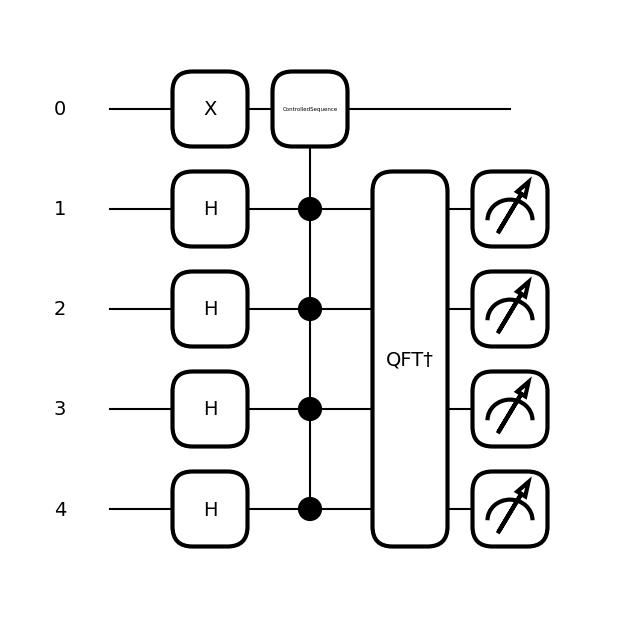

In [3]:
estimation_wires = range(1, 5)
qp.draw_mpl(circuit_qpe)(estimation_wires)

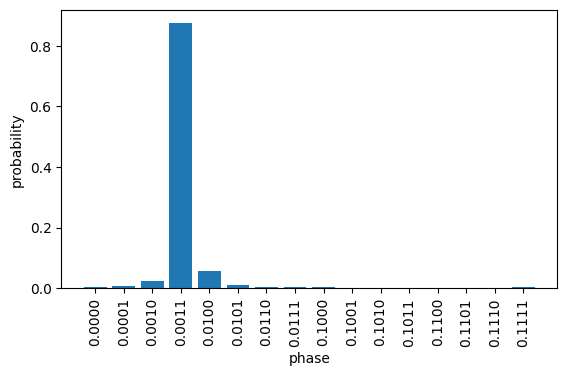

In [4]:
estimation_wires = range(1, 5)
results = circuit_qpe(estimation_wires)
bit_strings = [f"0.{x:0{len(estimation_wires)}b}" for x in range(len(results))]

plt.bar(bit_strings, results)
plt.xlabel("phase")
plt.ylabel("probability")
plt.xticks(rotation="vertical")
plt.subplots_adjust(bottom=0.3)
plt.show()

### Qiskit

In [5]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.circuit.library import QFT

C:\Users\tan\AppData\Local\Temp\ipykernel_18024\2641904055.py:27: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  qc.append(QFT(num_qubits=n_estimation, inverse=True), estimation_qubits)


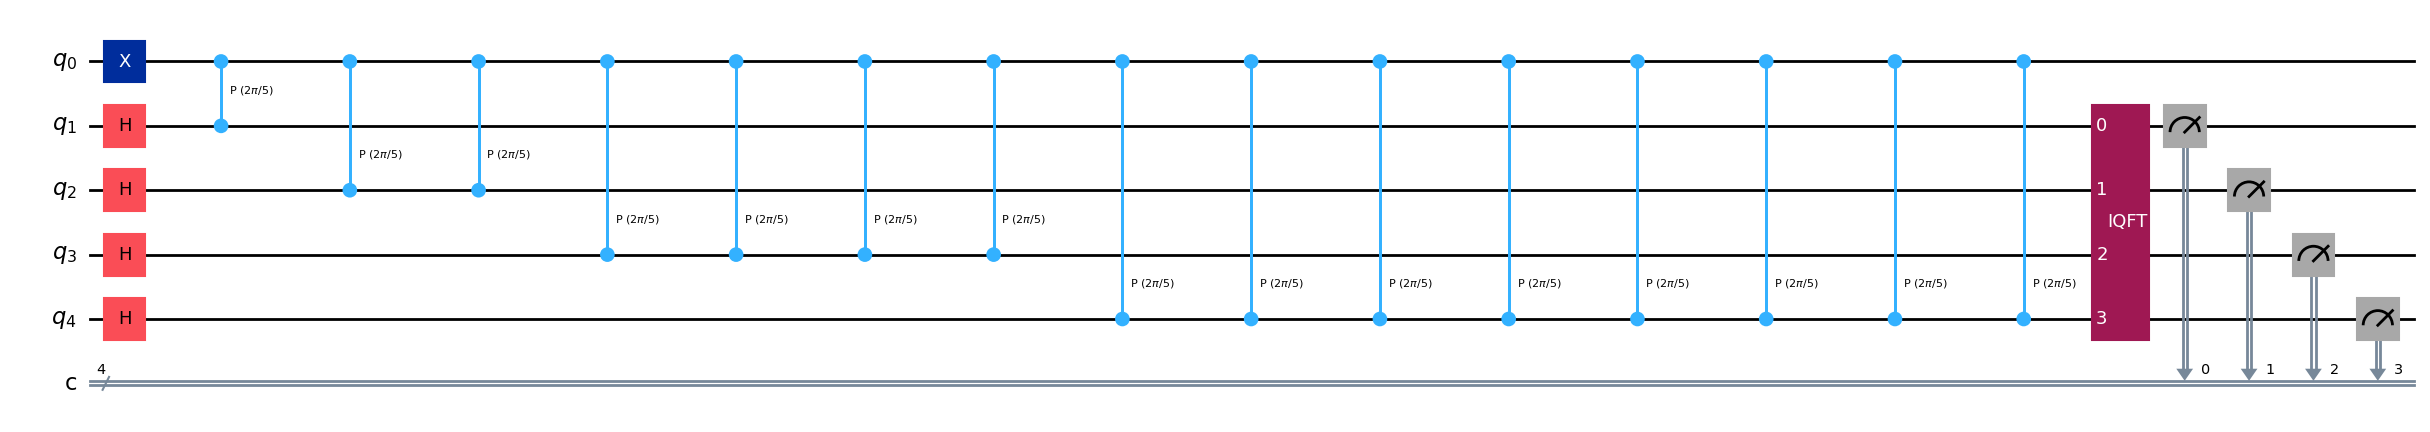

In [6]:
# parameters
n_estimation = 4
theta = 2 * np.pi / 5

# total qubits: 1 target + estimation qubits
n_total = 1 + n_estimation

qc = QuantumCircuit(n_total, n_estimation)

target = 0
estimation_qubits = list(range(1, n_total))

# |1> state on target
qc.x(target)

# Hadamards on estimation qubits
for q in estimation_qubits:
    qc.h(q)

# Controlled-U^(2^k)
for i, q in enumerate(estimation_qubits):
    repetitions = 2**i
    for _ in range(repetitions):
        qc.cp(theta, q, target)

# inverse QFT
qc.append(QFT(num_qubits=n_estimation, inverse=True), estimation_qubits)

# measurement
qc.measure(estimation_qubits, range(n_estimation))

# draw circuit
qc.draw("mpl", fold=-1)

In [7]:
from qiskit import transpile

sim = AerSimulator()
qc_transpiled = transpile(qc, sim)

result = sim.run(qc_transpiled, shots=1024).result()
counts = result.get_counts()

In [8]:
# sort results
counts = dict(sorted(counts.items()))

states = list(counts.keys())
probs = [counts[s] / 1024 for s in states]

# convert to "0.xxxx" format like your PennyLane code
bit_strings = [f"0.{s}" for s in states]

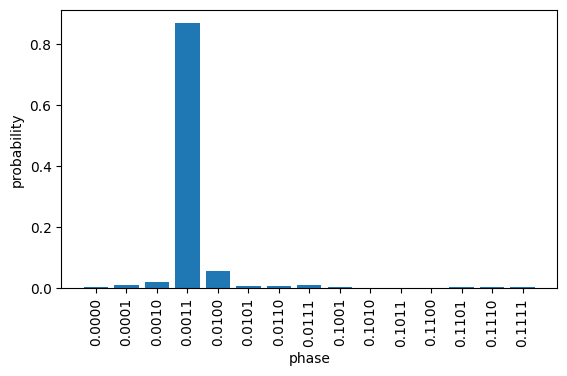

In [9]:
plt.bar(bit_strings, probs)
plt.xlabel("phase")
plt.ylabel("probability")
plt.xticks(rotation="vertical")
plt.subplots_adjust(bottom=0.3)
plt.show()